# Respuesta magnetotelúrica: unidades, orientación y período

**Pregunta:** ¿Cómo se transforman las impedancias medidas en curvas de resistividad aparente y fase, y qué no revelan esas curvas?

**Nivel 1 — Fundamentos**  
**Requisitos:** arreglos básicos y números complejos; 25 min.


## Objetivos

¿Qué cantidades medidas contiene la función de transferencia, cómo se comparan XY e YX y por qué la resistividad aparente no es una muestra de profundidad?

## Preparación

Esta lección lee el derivado comprometido y atribuido de cl061 y usa NumPy y Matplotlib. No descarga datos ni ajusta un modelo terrestre. La celda final de preparación informa las versiones exactas de los paquetes importados.

```bash
pip install numpy==2.2.6 matplotlib==3.10.8 scipy==1.15.2
```


In [1]:
# Registrar versiones exactas de las bibliotecas numéricas usadas en la lección.
from importlib.metadata import version

packages = ("numpy", "matplotlib", "scipy")
print({name: version(name) for name in packages})


{'numpy': '2.2.6', 'matplotlib': '3.10.8', 'scipy': '1.15.2'}


## Datos

El ejercicio usa el derivado EDI medido de 42 períodos de cl061, Clear Lake, cuya verdad del subsuelo se desconoce. Se citan el producto USGS y el registro de estación. El derivado permanece separado de la calibración sintética de dos capas; no se asigna verdad sintética a esta estación medida.

**Fuente y derechos:** La publicación USGS indica CC0; el EDI de estación solicita cita. Este repositorio usa el registro derivado QC atribuido y no replica una copia EDI original.


## Método

El método magnetotelúrico utiliza campos electromagnéticos que varían naturalmente. En una estación, el campo eléctrico horizontal se relaciona con el campo magnético horizontal mediante un tensor complejo dependiente de la frecuencia. Conviene empezar por la respuesta medida antes de dibujar una sección del subsuelo: los valores complejos, las unidades, la orientación y el eje de frecuencia determinan el significado de cualquier transformación posterior.

El producto almacena el tensor de impedancia como una matriz compleja de 2 por 2 para cada frecuencia. En este caso, las componentes fuera de la diagonal son las curvas principales; los términos diagonales y sus desviaciones se conservan para un filtro dimensional separado. XY e YX identifican componentes en los ejes declarados del marco fuente. No se deben intercambiar, promediar ni rotar silenciosamente si faltan geometría y covarianza necesarias.

Con la convención armónica registrada en la cadena de procesamiento, la relación es
$$\\mathbf{E}(f)=\\mathbf{Z}(f)\\mathbf{H}(f), \\qquad \\mathbf{Z}(f)=\\mathbf{Z}_{re}(f)+i\\mathbf{Z}_{im}(f).$$
f es frecuencia en hercios; E es el vector de campo eléctrico horizontal en voltios por metro; H es el vector de campo magnético horizontal en tesla; Z es impedancia en ohmios. i es la unidad imaginaria. Una función de transferencia compleja contiene amplitud y fase; descartar una parte elimina una característica distinta de la observación.

Para una componente fuera de la diagonal Zij, el período y la resistividad aparente convencional son
$$T=1/f, \\qquad \\rho_a=|Z_{ij}|^2/(\\mu_0 2\\pi f), \\qquad \\phi_{ij}=\\arg(Z_{ij}).$$
T se mide en segundos, mu0 es la permeabilidad del vacío, rho_a en ohmio-metro y la fase phi se muestra en grados. El código calcula la resistividad aparente independientemente desde el tensor complejo y la compara con los valores de respuesta comprometidos. La coincidencia reproduce unidades y asignación de componentes; no valida una interpretación geofísica de la fuente.

La convención de fase graficada es explícita: XY usa arg(Zxy), mientras que la curva recíproca YX usa arg(−Zyx), informada módulo 360 grados. La resistividad aparente usa la magnitud y no cambia con este signo. Conservar la convención es necesario para comparar curvas orientadas.\n\nLa palabra aparente importa. La fórmula transforma una función de transferencia superficial en una respuesta escalar usando la relación de referencia del semiespacio uniforme. En una Tierra estratificada o multidimensional, la curva depende de la respuesta electromagnética integrada y no es la resistividad verdadera a una profundidad puntual. A menudo se asocia un período con una escala característica de difusión. Bajo la aproximación de semiespacio uniforme, delta es aproximadamente sqrt(2 rho/(mu0 omega)); usando omega=2 pi f y unidades convencionales resulta cerca de 503 sqrt(rho_a T) metros. Solo orienta una escala. Aquí el tensor falla el filtro 1D necesario, por lo que esta aproximación no afirma profundidad de investigación ni un límite de capa en cl061.

Inspeccione XY e YX por separado. Si divergen, las causas posibles incluyen dimensionalidad, distorsión galvánica, errores de orientación, diferencias de procesamiento o incertidumbre; el gráfico por sí solo no puede elegir entre ellas. Las frecuencias no están espaciadas por igual en aritmética ordinaria, así que el eje logarítmico de período presenta el rango amplio sin fingir muestreo lineal uniforme. El gráfico del plano complejo traza impedancia real frente a imaginaria y colorea por período; hace visibles rotación de fase y cambio de amplitud sin reemplazar las curvas indexadas por frecuencia.

Para esta estación medida, las curvas son una descripción inicial. Las desviaciones diagonales y antisimétricas fallan el filtro 1D necesario del producto, faltan dos períodos del tipper y se desconoce la verdad del subsuelo. No infiera un modelo 1D a partir de estas curvas. La siguiente lección aplica el filtro real y estudia su sensibilidad. Una calibración sintética separada sirve para aprender el problema directo e inverso, pero sigue siendo otra clase de datos y nunca aporta una verdad oculta para cl061.

Un registro de función de transferencia viene después de adquirir y procesar series temporales; no equivale a las trazas eléctricas y magnéticas originales. La respuesta instrumental, orientación de sensores, contacto en el sitio, decisiones de referencia remota e incertidumbre del estimador pueden afectar el tensor estimado. Este ejercicio empieza en una respuesta EDI derivada y atribuida; una curva no permite auditar por sí sola todas las decisiones de adquisición. Para datos nuevos conserva junto a los arreglos el hash del archivo, metadatos de estación, convención de coordenadas, rotación declarada, software y versión de procesamiento, y representación del error.

El plano complejo ayuda a detectar errores de convención. Un cambio de signo desplaza una componente media vuelta sin cambiar su magnitud, así que la resistividad aparente por sí sola no revela un problema de polaridad. La fase YX graficada sigue la convención del producto arg(−Zyx), mientras XY usa arg(Zxy); ambas se expresan en grados positivos. Por eso la fase se compara con la respuesta comprometida específica de cada orientación, en vez de recalcularla con una fórmula angular sin convención. Un adaptador robusto hace explícitas estas decisiones y las prueba frente a una respuesta conocida independiente.

El color del plano complejo codifica período, no profundidad. El gráfico sigue cada componente en el espacio de frecuencia; no ubica un punto bajo tierra. La escala 503 sqrt(rho_a T) es solo una guía de semiespacio homogéneo. Contrastes de conductividad, dimensionalidad, anisotropía y distorsión galvánica superficial cambian la respuesta. Por ello, el filtro tensorial necesario de la siguiente lección habilita una familia de modelos declarada; no prueba dimensionalidad geológica.


In [2]:
# Recalcular las curvas observadas de cl061 con la conversión del producto.
import json
import sys
from pathlib import Path
import numpy as np
from importlib.metadata import version

root = next(path for path in (Path.cwd(), *Path.cwd().parents)
            if (path / "data").is_dir() and (path / "data-pipeline").is_dir())
sys.path.insert(0, str(root / "data-pipeline"))
import electromagnetics as em

case = json.loads((root / "data/derived/v2/edi/clear-lake-cl061-screen.json").read_text(encoding="utf-8"))
frequency = np.asarray(case["frequencies_hz"], dtype=float)
period = 1.0 / frequency
z = np.asarray(case["tensor"]["real"], dtype=float) + 1j * np.asarray(case["tensor"]["imag"], dtype=float)
computed = {}
for component, i, j, sign in (("xy", 0, 1, 1.0), ("yx", 1, 0, -1.0)):
    curves = em.curves(sign * z[:, i, j], frequency)
    rho = np.asarray(curves["apparent"])
    phase = np.mod(np.asarray(curves["phase"]), 360.0)
    stored = case["observed"][component]
    assert np.allclose(rho, stored["apparent"], rtol=2e-10, atol=1e-10)
    assert np.allclose(phase, stored["phase"], rtol=0, atol=1e-10)
    computed[component] = (rho, phase)
print("Entorno:", {name: version(name) for name in ("numpy", "matplotlib", "scipy")})
print("Registro:", case["id"], case["source_kind"], "períodos:", len(period), "verdad:", case["truth"])
print("Las curvas del producto reproducen resistividad aparente y fase XY/YX.")
print("Elegible para inversión 1D:", case["one_d_inversion_eligible"], "(esta lección no invierte cl061)")


Entorno: {'numpy': '2.2.6', 'matplotlib': '3.10.8', 'scipy': '1.15.2'}
Registro: cl061 measured EDI transfer functions períodos: 42 verdad: None
Las curvas del producto reproducen resistividad aparente y fase XY/YX.
Elegible para inversión 1D: False (esta lección no invierte cl061)


### Recalcular la respuesta estratificada en un modelo sintético aparte

Este control directo usa la recurrencia del producto para un modelo declarado de dos capas. Muestra cómo resistividad y espesor generan una impedancia compleja dependiente de frecuencia y cómo se transforma en resistividad aparente y fase. El modelo sintético es una calibración propia; no sustituye la respuesta medida de cl061 ni afirma conocer su subsuelo.


In [3]:
# Ejecutar el método directo del producto en un control sintético de dos capas.
synthetic_frequency = np.logspace(-2, 2, 24)
synthetic_rho = np.array([180.0, 20.0])
synthetic_thickness = np.array([450.0])
synthetic_z = em.impedance(synthetic_rho, synthetic_thickness, synthetic_frequency)
synthetic_curves = em.curves(synthetic_z, synthetic_frequency)
print("Modelo sintético Ω·m:", synthetic_rho, "espesor m:", synthetic_thickness)
print("Respuesta compleja finita:", bool(np.isfinite(synthetic_z).all()))
print("Resistividad aparente mediana Ω·m:", float(np.median(synthetic_curves["apparent"])))


Modelo sintético Ω·m: [180.  20.] espesor m: [450.]
Respuesta compleja finita: True
Resistividad aparente mediana Ω·m: 28.388426393359005


### Evaluar un objetivo residual sintético fijo

Se añade una perturbación con semilla a la respuesta sintética y el objetivo del producto informa el vector residual en el modelo conocido. No se optimiza ningún parámetro ni se ajusta una estación de terreno. Así se separan respuesta directa, observaciones/error declarado y evaluación del objetivo antes de introducir un problema inverso.


In [4]:
# Puntuar una respuesta sintética ruidosa con semilla, sin ajustar parámetros.
rng = np.random.default_rng(20261121)
sigma = np.maximum(0.03 * np.abs(synthetic_z), 1e-12)
noise = sigma * (rng.standard_normal(len(sigma)) + 1j * rng.standard_normal(len(sigma)))
synthetic_observed = synthetic_z + noise
residual = em.objective_residual(
    np.log(synthetic_rho), synthetic_thickness, synthetic_frequency,
    synthetic_observed, sigma, beta=0.001,
)
print("Observaciones complejas sintéticas:", len(synthetic_frequency))
print("Norma del vector objetivo normalizado:", float(np.linalg.norm(residual)))


Observaciones complejas sintéticas: 24
Norma del vector objetivo normalizado: 0.9929920469899495


### Leer las curvas de respuesta observadas

La conversión del producto coincide con los arreglos comprometidos de resistividad aparente y fase de cl061 en los 42 períodos. Las curvas XY y YX con el signo declarado conservan orientación y convención de fase. Son observables derivados en superficie; su forma no es una sección de profundidad ni revierte la falla de elegibilidad unidimensional de la estación.


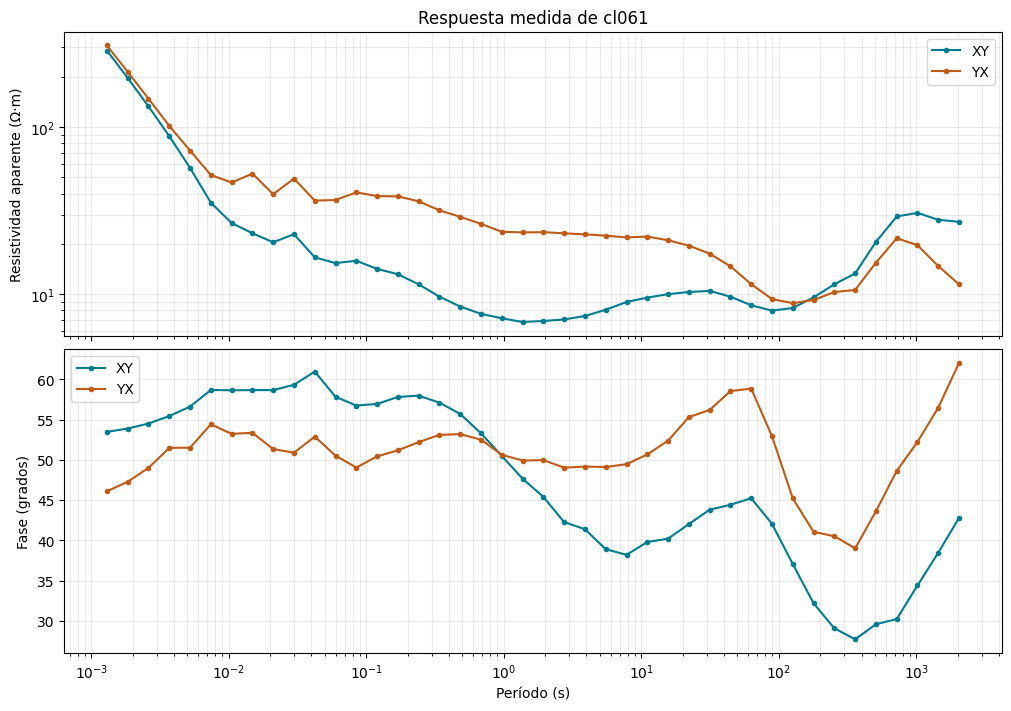

In [5]:
# Graficar resistividad aparente y fase medidas para ambas orientaciones.
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 1, figsize=(10, 7), constrained_layout=True, sharex=True)
for component, color in (("xy", "#007c91"), ("yx", "#bf5b17")):
    rho, phase = computed[component]
    axes[0].loglog(period, rho, ".-", color=color, label=component.upper())
    axes[1].semilogx(period, phase, ".-", color=color, label=component.upper())
axes[0].set_ylabel("Resistividad aparente (Ω·m)")
axes[0].set_title("Respuesta medida de cl061")
axes[1].set_ylabel("Fase (grados)")
axes[1].set_xlabel("Período (s)")
for axis in axes:
    axis.grid(True, which="both", alpha=0.25)
    axis.legend()
plt.show()


Ambos paneles comparten el eje de período para comparar orientaciones en cada medición. La resistividad aparente se deriva de la magnitud de impedancia y la fase depende del argumento complejo y del signo YX declarado. La estación sigue siendo un ejemplo medido para QC con subsuelo desconocido; ninguna curva se presenta como una capa recuperada.


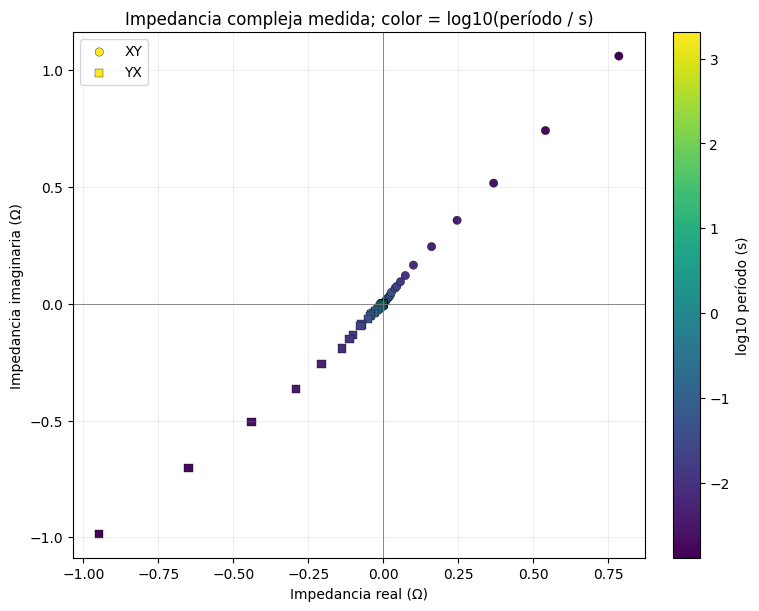

In [6]:
# Graficar los componentes complejos medidos y codificar el período con color.
fig_complex, ax = plt.subplots(figsize=(7.5, 6), constrained_layout=True)
for component, i, j, marker in (("xy", 0, 1, "o"), ("yx", 1, 0, "s")):
    points = ax.scatter(
        z[:, i, j].real, z[:, i, j].imag, c=np.log10(period),
        cmap="viridis", marker=marker, label=component.upper(),
        edgecolors="black", linewidths=0.25,
    )
ax.set_xlabel("Impedancia real (Ω)")
ax.set_ylabel("Impedancia imaginaria (Ω)")
ax.set_title("Impedancia compleja medida; color = log10(período / s)")
ax.axhline(0, color="#777777", lw=0.6)
ax.axvline(0, color="#777777", lw=0.6)
ax.grid(True, alpha=0.2)
ax.legend()
fig_complex.colorbar(points, ax=ax, label="log10 período (s)")
plt.show()


Cada marcador representa un componente del tensor complejo medido en un período; el color indica período, no profundidad. El recorrido puede mostrar cambios de fase y amplitud, pero no demuestra que una tierra unidimensional explique los datos. La compuerta tensorial y los metadatos siguen condicionando la interpretación, por lo que esta vista compleja no habilita una inversión estratificada.


## Resultados

**Respuesta:** **Respuesta:** El cálculo de impedancia a respuesta reproduce ambas orientaciones comprometidas dentro de la tolerancia de coma flotante. Para fase, el producto usa arg(Zxy) y arg(−Zyx), expresados entre 0 y 360 grados; la resistividad aparente depende de la magnitud y no cambia con ese signo. Los gráficos describen observaciones superficiales. No estiman resistividad de capas ni profundidad de investigación. cl061 sigue siendo un conjunto medido solo-QC y aquí se desconoce la verdad del subsuelo.

## Resumen

La resistividad aparente y la fase son vistas derivadas de la impedancia compleja superficial. Su significado físico depende de unidades, marco, frecuencia y dimensionalidad. cl061 medido falla el filtro 1D declarado y aquí no tiene verdad conocida del subsuelo; usa los gráficos para QC de respuesta, no como geología rotulada por profundidad.

## Referencias

- [Caldwell, Bibby y Brown (2004), The magnetotelluric phase tensor](https://doi.org/10.1111/j.1365-246X.2004.02281.x)
- [Datos magnetotelúricos USGS de Clear Lake](https://www.usgs.gov/data/magnetotelluric-data-clear-lake-region-northern-california)
- [Producto de estación cl061 de EarthScope/USGS](https://data.earthscope.org/app/products/portal/emtf/emtf_item.html?p=2022%2FMT_TF_USGS-GMEG.2022.cl061)
- [Kirkby et al. (2019), software MTPy, DOI JOSS 10.21105/joss.01358](https://doi.org/10.21105/joss.01358)
- [Krieger y Peacock (2014), toolbox MTpy, DOI 10.1016/j.cageo.2014.07.013](https://doi.org/10.1016/j.cageo.2014.07.013)